In [9]:
from pystlouisfed import FRED
import os
import numpy as np
import pandas as pd
from datetime import date, timedelta

from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter


In [10]:
key = os.getenv("FRED_API_KEY")
fred = FRED(api_key=key)

In [11]:
RT = date.today() - timedelta(days=1)

def getData(name, start, end, d, realtime_start=RT, realtime_end=RT):
    df = fred.series_observations(name,
                                  observation_start=start,
                                  observation_end=end,
                                  realtime_start=realtime_start,
                                  realtime_end=realtime_end)
    df["duration"] = d
    return df

In [12]:
start = "2000-01-01"
end = "2026-09-30"
dataframe = pd.concat([getData("DGS1", start, end, 1),
                       getData("DGS2", start, end, 2),
                       getData("DGS7", start, end, 7),
                       getData("DGS10", start, end, 10)])

In [13]:
def moddur_par(y, T, n=2):
    return (1 - (1 + y / n) ** (-n * T)) / y

In [14]:
dataframe['mod_duration'] = moddur_par(pd.to_numeric(dataframe["value"], errors="coerce") / 100, dataframe['duration'])

In [15]:
wide = (dataframe
        .pivot_table(index="date", columns="duration", values=["value", "mod_duration"])
        .dropna())                                   
wide.columns = [f"{v}_{d}" for v, d in wide.columns]

wide["ratio"] = wide["mod_duration_10"] / wide["mod_duration_2"]   
wide["spread_bp"] = (wide["value_10"] - wide["value_2"]) * 100      

In [16]:
TARGET_DV01 = 10000         

wide["notional_2"]  = TARGET_DV01 / (wide["mod_duration_2"]  * 1e-4)  
wide["notional_10"] = TARGET_DV01 / (wide["mod_duration_10"] * 1e-4)  


wide["dv01_2"]  = wide["mod_duration_2"]  * wide["notional_2"]  * 1e-4
wide["dv01_10"] = wide["mod_duration_10"] * wide["notional_10"] * 1e-4

wide[["notional_2", "notional_10", "dv01_2", "dv01_10", "ratio"]].head()

,notional_2,notional_10,dv01_2,dv01_10,ratio
date,,,,,
2000-01-03,5.405009e+07,1.380615e+07,10000.0,10000.0,3.914928
2000-01-04,5.399854e+07,1.374949e+07,10000.0,10000.0,3.927313
2000-01-05,5.405009e+07,1.383138e+07,10000.0,10000.0,3.907788
2000-01-06,5.403076e+07,1.379985e+07,10000.0,10000.0,3.915315
2000-01-07,5.400498e+07,1.376836e+07,10000.0,10000.0,3.922397


In [17]:
wide["date"] = pd.to_datetime(wide.index)
monthly = wide.resample("ME").last()   
dff = pd.to_numeric(fred.series_observations("DFF", observation_start=start, realtime_start=RT, realtime_end=RT)["value"],
                    errors="coerce").dropna()

In [18]:
monthly = wide.resample("ME").last()       
monthly["r"] = dff.resample("ME").mean()

monthly["notional_2"]  = TARGET_DV01 / (monthly["mod_duration_2"]  * 1e-4)
monthly["notional_10"] = TARGET_DV01 / (monthly["mod_duration_10"] * 1e-4)
monthly["spread_bp"]   = (monthly["value_10"] - monthly["value_2"]) * 100
monthly["s2_bp"]  = (monthly["value_2"]  - monthly["value_1"]) * 100
monthly["s10_bp"] = (monthly["value_10"] - monthly["value_7"]) * 100 / 3

lag = monthly.shift(1)
dt  = monthly.index.to_series().diff().dt.days / 365

monthly["pnl_spread"] = TARGET_DV01 * monthly["spread_bp"].diff()
monthly["carry"] = (lag["notional_2"]  * (lag["value_2"]  - monthly["r"]) / 100
                  - lag["notional_10"] * (lag["value_10"] - monthly["r"]) / 100) * dt
monthly["roll"]  = TARGET_DV01 * (lag["s2_bp"] - lag["s10_bp"]) * dt
monthly["carry_roll"] = monthly["carry"] + monthly["roll"]
monthly["total"]      = monthly["pnl_spread"] + monthly["carry_roll"]

In [19]:
usrec = pd.to_numeric(fred.series_observations("USREC", observation_start="1990-01-01", realtime_start=RT, realtime_end=RT)["value"],
                      errors="coerce").resample("ME").last()

def phases(usrec, r, early_months=18, hike_bp=50):
    df = pd.concat({"rec": usrec, "r": r}, axis=1).dropna()
    since, cnt = [], 10**6
    for x in df["rec"]:
        cnt = 0 if x == 1 else cnt + 1         
        since.append(cnt)
    since = pd.Series(since, index=df.index)
    hike = df["r"].diff(6) * 100 > hike_bp      
    ph = np.where(df["rec"] == 1, "recession",
         np.where(since <= early_months, "early",
         np.where(hike, "late", "mid")))
    return pd.Series(ph, index=df.index, name="phase")

monthly["phase"] = phases(usrec, monthly["r"])

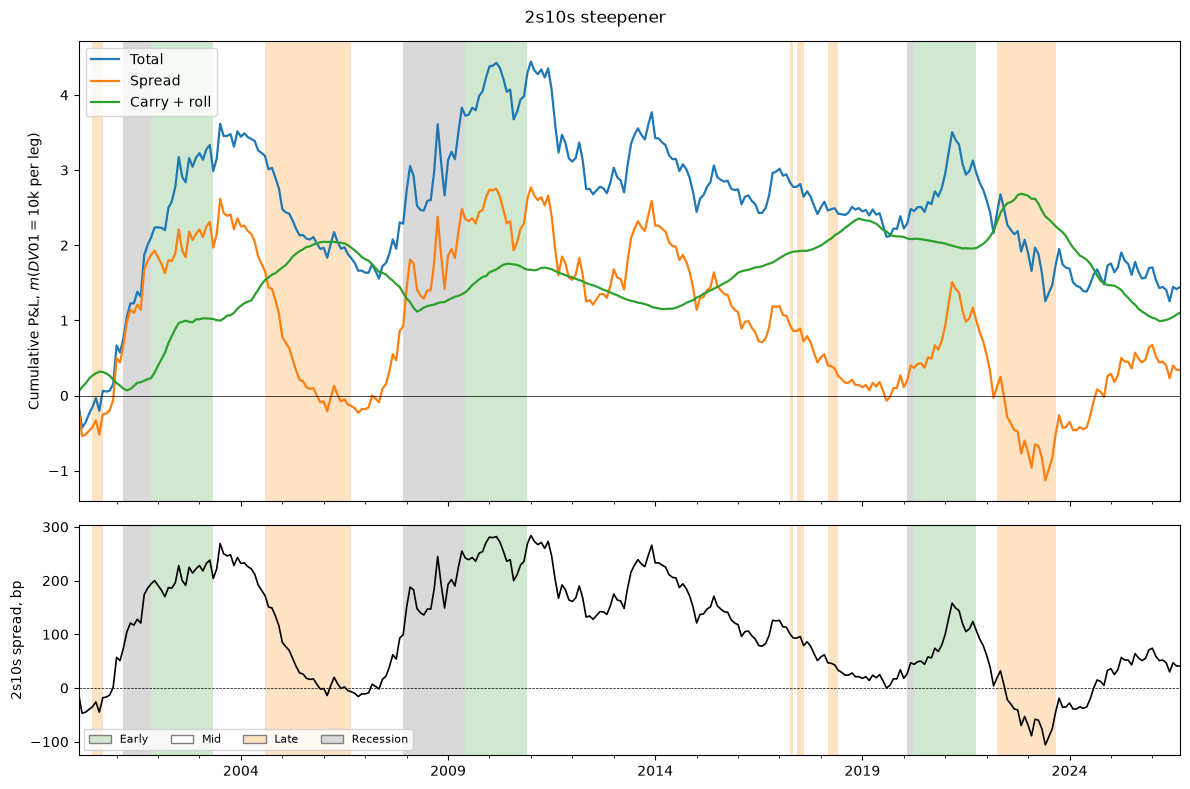

In [20]:
import matplotlib.pyplot as plt

COLORS = {"early": "#cfe8cf", "mid": "#ffffff", "late": "#fde2c4", "recession": "#d9d9d9"}

def shade(ax, ph):
    blocks = (ph != ph.shift()).cumsum()                
    for _, g in ph.groupby(blocks):
        c = COLORS[g.iloc[0]]
        if c != "#ffffff":
            ax.axvspan(g.index[0] - pd.offsets.MonthEnd(1), g.index[-1],
                       color=c, lw=0, zorder=0)

m = monthly.dropna(subset=["total"])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})

(m[["total", "pnl_spread", "carry_roll"]].cumsum() / 1e6).plot(ax=a1, lw=1.6)
a1.set_ylabel("Cumulative P&L, $m (DV01 = $10k per leg)")
a1.legend(["Total", "Spread", "Carry + roll"], loc="upper left")
a1.axhline(0, color="k", lw=0.5)

m["spread_bp"].plot(ax=a2, color="k", lw=1.2)
a2.axhline(0, color="k", lw=0.5, ls="--")
a2.set_ylabel("2s10s spread, bp")
a2.set_xlabel("")

for ax in (a1, a2):
    shade(ax, m["phase"])
a2.legend([plt.Rectangle((0, 0), 1, 1, color=c, ec="grey") for c in COLORS.values()],
          [k.capitalize() for k in COLORS], loc="lower left", ncol=4, fontsize=8)

fig.suptitle("2s10s steepener")
fig.tight_layout()
fig.savefig("steepener_2s10s.png", dpi=150)
plt.show()

In [21]:
CAPITAL = 10_000_000
COLS = ["pnl_spread", "carry_roll", "total"]
COMP = [("pnl_spread", "Spread"), ("carry_roll", "Carry + roll"), ("total", "Steepener")]
PHASES = [("early", "Early"), ("mid", "Mid"), ("late", "Late"), ("recession", "Recession")]

def _mdd(pnl, capital):
    eq = capital + pnl.cumsum()
    peak = eq.cummax().clip(lower=capital)
    return (eq / peak - 1).min()

def _stats(pnl, capital):
    r = pnl / capital
    sd = r.std()
    return {"ret": r.mean() * 12,
            "vol": sd * np.sqrt(12),
            "sharpe": r.mean() / sd * np.sqrt(12) if sd > 0 else np.nan,
            "mdd": _mdd(pnl, capital)}

def _episode_mdd(pnl, phase, which, capital):
    blk = (phase != phase.shift()).cumsum()
    worst = 0.0
    for _, idx in pnl.groupby(blk).groups.items():
        if phase.loc[idx[0]] == which:
            worst = min(worst, _mdd(pnl.loc[idx], capital))
    return worst

F_TITLE = Font(name="Arial", size=14)
F_HEAD  = Font(name="Arial", size=9, bold=True)
F_BODY  = Font(name="Arial", size=9)
F_NOTE  = Font(name="Arial", size=8, italic=True, color="595959")
FILL_H1 = PatternFill("solid", start_color="F4B183")
FILL_H2 = PatternFill("solid", start_color="FBE5D6")
THIN = Side(style="thin", color="000000")
BOX  = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)
CENTER = Alignment(horizontal="center", vertical="center", wrap_text=True)
RIGHT  = Alignment(horizontal="right", vertical="center")
LEFT   = Alignment(horizontal="left", vertical="center")
PCT, NUM2, USD = "0.00%", "0.00", '#,##0;(#,##0);"-"'

def _cell(ws, r, c, v=None, font=F_BODY, fill=None, fmt=None, align=RIGHT, border=True):
    cell = ws.cell(row=r, column=c, value=v)
    cell.font, cell.alignment = font, align
    if fill: cell.fill = fill
    if fmt: cell.number_format = fmt
    if border: cell.border = BOX
    return cell

def _merge(ws, r1, c1, r2, c2, v, font=F_HEAD, fill=FILL_H1):
    for rr in range(r1, r2 + 1):
        for cc in range(c1, c2 + 1):
            _cell(ws, rr, cc, None, font, fill, align=CENTER)
    ws.merge_cells(start_row=r1, start_column=c1, end_row=r2, end_column=c2)
    ws.cell(row=r1, column=c1, value=v)

def build_report(m, capital, dv01, chart_png="steepener_2s10s.png",
                 path="steepener_2s10s_report.xlsx"):
    m = m.dropna(subset=["total"]).copy()
    m["date"] = pd.to_datetime(m["date"])
    wb = Workbook()
    ws = wb.active
    ws.title = "Report"
    ws.sheet_view.showGridLines = False
    ws.column_dimensions["A"].width = 2
    ws.column_dimensions["B"].width = 13
    for c in range(3, 16):
        ws.column_dimensions[get_column_letter(c)].width = 12.5

    r0 = 2
    _cell(ws, r0, 2, "Annualized metrics by year", F_TITLE, align=LEFT, border=False)
    groups = [("Return", "ret", PCT), ("Volatility", "vol", PCT),
              ("Sharpe", "sharpe", NUM2), ("Max drawdown", "mdd", PCT)]
    _merge(ws, r0 + 1, 2, r0 + 2, 2, "Metric")
    for g, (gname, _, _) in enumerate(groups):
        c = 3 + 3 * g
        _merge(ws, r0 + 1, c, r0 + 1, c + 2, gname)
        for k, (_, lab) in enumerate(COMP):
            _cell(ws, r0 + 2, c + k, lab, F_HEAD, FILL_H2, align=CENTER)
    _cell(ws, r0 + 1, 15, "Financing", F_HEAD, FILL_H1, align=CENTER)
    _cell(ws, r0 + 2, 15, "Fed funds (avg)", F_HEAD, FILL_H2, align=CENTER)
    _cell(ws, r0 + 3, 2, "Year", F_HEAD, FILL_H2, align=CENTER)
    for c in range(3, 16):
        _cell(ws, r0 + 3, c)

    row = r0 + 4
    partial = []
    for yr, g in m.groupby(m.index.year):
        lab = str(yr)
        if len(g) < 12:
            partial.append(f"{yr}: {len(g)} months")
        _cell(ws, row, 2, lab, F_BODY, FILL_H2, align=CENTER)
        st = {k: _stats(g[k], capital) for k, _ in COMP}
        for gi, (_, key, fmt) in enumerate(groups):
            for k, (col, _) in enumerate(COMP):
                v = st[col][key]
                if key == "ret":
                    v = g[col].sum() / capital
                _cell(ws, row, 3 + 3 * gi + k, None if pd.isna(v) else float(v), fmt=fmt)
        _cell(ws, row, 15, float(g["r"].mean() / 100), fmt=PCT)
        row += 1
   

    row += 1
    p0 = row
    _cell(ws, p0, 2, "Metrics by cycle phase", F_TITLE, align=LEFT, border=False)
    hdr = ["Phase", "Metric"] + [lab for _, lab in COMP]
    for j, h in enumerate(hdr):
        _cell(ws, p0 + 1, 2 + j, h, F_HEAD, FILL_H1, align=CENTER)
    row = p0 + 2
    metric_rows = [("Ann. return", "ret", PCT), ("Ann. volatility", "vol", PCT),
                   ("Sharpe", "sharpe", NUM2), ("Max drawdown", "mdd", PCT)]
    for key, lab in PHASES:
        g = m[m["phase"] == key]
        if g.empty:
            continue
        _merge(ws, row, 2, row + len(metric_rows) - 1, 2,
               f"{lab}\n{len(g)} months", font=F_BODY, fill=FILL_H2)
        for i, (mlab, mkey, fmt) in enumerate(metric_rows):
            _cell(ws, row + i, 3, mlab, align=LEFT)
            for k, (col, _) in enumerate(COMP):
                if mkey == "mdd":
                    v = _episode_mdd(m[col], m["phase"], key, capital)
                else:
                    v = _stats(g[col], capital)[mkey]
                _cell(ws, row + i, 4 + k, None if pd.isna(v) else float(v), fmt=fmt)
        row += len(metric_rows)
    
    row += 2

    f0 = row
    _cell(ws, f0, 2, "Metrics for full period", F_TITLE, align=LEFT, border=False)
    _cell(ws, f0 + 1, 2, "", F_HEAD, FILL_H1)
    _cell(ws, f0 + 1, 3, "", F_HEAD, FILL_H1)
    ws.merge_cells(start_row=f0 + 1, start_column=2, end_row=f0 + 1, end_column=3)
    for k, (_, lab) in enumerate(COMP):
        _cell(ws, f0 + 1, 4 + k, lab, F_HEAD, FILL_H1, align=CENTER)
    full = []
    for col, _ in COMP:
        p = m[col]; r = p / capital; st = _stats(p, capital)
        full.append({
            "Ann. return": (st["ret"], PCT),
            "Ann. volatility": (st["vol"], PCT),
            "Sharpe": (st["sharpe"], NUM2),
            "Max drawdown": (st["mdd"], PCT),
            "Cumulative return": (r.sum(), PCT),
            "Cumulative P&L, $": (p.sum(), USD),
            "Avg P&L, bp of spread / year": (p.mean() * 12 / dv01, NUM2),
            "t-stat (mean)": (r.mean() / (r.std() / np.sqrt(len(r))), NUM2),
            "% positive months": ((p > 0).mean(), PCT),
            "Best month": (r.max(), PCT),
            "Worst month": (r.min(), PCT),
        })
    row = f0 + 2
    for name in full[0]:
        _cell(ws, row, 2, name, align=LEFT)
        _cell(ws, row, 3, None)
        ws.merge_cells(start_row=row, start_column=2, end_row=row, end_column=3)
        for k in range(3):
            v, fmt = full[k][name]
            _cell(ws, row, 4 + k, None if pd.isna(v) else float(v), fmt=fmt)
        row += 1

    row += 1
    
    try:
        img = XLImage(chart_png)
        scale = 820 / img.width
        img.width, img.height = img.width * scale, img.height * scale
        ws.add_image(img, f"H{p0 + 1}")
    except FileNotFoundError:
        print(f"Chart {chart_png} not found: save it first with fig.savefig(...)")

    ws.page_setup.orientation = "landscape"
    ws.page_setup.fitToWidth, ws.page_setup.fitToHeight = 1, 0
    ws.sheet_properties.pageSetUpPr.fitToPage = True

    ws2 = wb.create_sheet("Monthly data")
    cols = ["date", "phase", "value_2", "value_10", "spread_bp", "r",
            "notional_2", "notional_10", "pnl_spread", "carry", "roll", "carry_roll", "total"]
    cols = [c for c in cols if c in m.columns]
    for j, c in enumerate(cols, start=1):
        _cell(ws2, 1, j, c, F_HEAD, FILL_H1, align=CENTER)
        ws2.column_dimensions[get_column_letter(j)].width = 13
    for i, (_, rr) in enumerate(m[cols].iterrows(), start=2):
        for j, c in enumerate(cols, start=1):
            v = rr[c]
            if c == "date":
                v = v.to_pydatetime(); fmt = "yyyy-mm-dd"
            elif c in ("phase",):
                fmt = None
            elif c in ("value_2", "value_10", "r", "spread_bp"):
                fmt = "0.00"
            else:
                fmt = USD
            _cell(ws2, i, j, v if not (isinstance(v, float) and np.isnan(v)) else None,
                  fmt=fmt, align=CENTER if c == "phase" else RIGHT)
    ws2.freeze_panes = "B2"

    wb.save(path)
    print("saved", path)

if __name__ == "__main__":
    build_report(m, CAPITAL, TARGET_DV01)

saved steepener_2s10s_report.xlsx
